In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [3]:
!pip install -q datasets

from datasets import load_dataset

# Load TinyStories
dataset = load_dataset("roneneldan/TinyStories")

# For now, use only a small subset so training finishes in Colab
stories = dataset["train"]["text"][:500]

# Merge all stories into one long string
tiny_stories_text = "\n\n".join(stories)

print(f"Characters: {len(tiny_stories_text):,}")
print(tiny_stories_text[:500])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Characters: 403,432
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b


In [4]:
tiny_stories_text

'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.\n\nLily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."\n\nTogether, they shared the needle and sewed the button on Lily\'s shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.\n\nOnce upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.\n\nOne day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were

In [5]:
len(tiny_stories_text)

403432

In [6]:
import re
text="Hello, Myself Nishkarsh Pahuja. From IITH."
result=re.split(r'([,.:;?_!"()\']|--|\s)', tiny_stories_text)
preprocessed=([item.strip() for item in result if item.strip()])
print(preprocessed)

['One', 'day', ',', 'a', 'little', 'girl', 'named', 'Lily', 'found', 'a', 'needle', 'in', 'her', 'room', '.', 'She', 'knew', 'it', 'was', 'difficult', 'to', 'play', 'with', 'it', 'because', 'it', 'was', 'sharp', '.', 'Lily', 'wanted', 'to', 'share', 'the', 'needle', 'with', 'her', 'mom', ',', 'so', 'she', 'could', 'sew', 'a', 'button', 'on', 'her', 'shirt', '.', 'Lily', 'went', 'to', 'her', 'mom', 'and', 'said', ',', '"', 'Mom', ',', 'I', 'found', 'this', 'needle', '.', 'Can', 'you', 'share', 'it', 'with', 'me', 'and', 'sew', 'my', 'shirt', '?', '"', 'Her', 'mom', 'smiled', 'and', 'said', ',', '"', 'Yes', ',', 'Lily', ',', 'we', 'can', 'share', 'the', 'needle', 'and', 'fix', 'your', 'shirt', '.', '"', 'Together', ',', 'they', 'shared', 'the', 'needle', 'and', 'sewed', 'the', 'button', 'on', 'Lily', "'", 's', 'shirt', '.', 'It', 'was', 'not', 'difficult', 'for', 'them', 'because', 'they', 'were', 'sharing', 'and', 'helping', 'each', 'other', '.', 'After', 'they', 'finished', ',', 'Lily'

In [7]:
len(preprocessed)

91806

In [8]:
sort=sorted(set(preprocessed))
print(sort)
vocab_size=(len(sort))

['!', '"', '$10', "'", ',', '-', '--', '.', '2', '3', '3-years-old', '3rd', '8', ':', ';', '?', 'A', 'Abigail', 'Acceptor', 'After', 'Afterwards', 'Ah', 'Ahhh', 'Alas', 'Alfie', 'Ali', 'Alice', 'All', 'Although', 'Always', 'Amy', 'An', 'And', 'Andy', 'Ann', 'Anna', 'Annie', 'Anyone', 'Arctic', 'Are', 'As', 'Asked', 'At', 'Baby', 'Be', 'Bear', 'Because', 'Becky', 'Bee', 'Beep', 'Before', 'Behind', 'Being', 'Bella', 'Ben', 'Benny', 'Bennyâ€™s', 'Better', 'Beware', 'Bill', 'Billy', 'Billyâ€™s', 'Binky', 'Bless', 'Bloom', 'Bob', 'Both', 'Bruce', 'But', 'By', 'C', 'Can', 'Carefully', 'Caw', 'Charles', 'Charlie', 'Chloe', 'Cindy', 'Claire', 'Clarissa', 'Come', 'Coo-Coo', 'Counting', 'Crow', 'Curious', 'Dad', 'Daddy', 'Daisy', 'Dangerous', 'Danny', 'Dave', 'Denise', 'Dependable', 'Despite', 'Did', 'Dinosaur', 'Do', 'Doesn', 'Don', 'Donâ€™t', 'Each', 'Ella', 'Elly', 'Emily', 'Emma', 'Emmy', 'End', 'Even', 'Eventually', 'Every', 'Everyday', 'Everyone', 'Everything', 'Everywhere', 'Excited', 'Ex

In [9]:
vocab={token:integer for integer,token in enumerate(sort)}
#for word, idx in vocab.items():
#    print(word, idx)

In [10]:
class SimpleTokenizerV1:
  def __init__(self, vocab):
    self.str_to_int = vocab
    self.int_to_str = {i:s for s,i in vocab.items()}

  def encode(self, text):
    preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed = [
      item.strip() for item in preprocessed if item.strip()
    ]

    ids=[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text = " ".join([self.int_to_str[i] for i in ids])
    text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text

In [11]:
tokenizer = SimpleTokenizerV1(vocab)

In [12]:
text = """The little girl was happy."""

In [13]:
ids = tokenizer.encode(text)
print(ids)

[347, 1937, 1495, 3448, 1600, 7]


In [14]:
tokenizer.decode(ids)

'The little girl was happy.'

In [15]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab = {token:integer for integer, token in enumerate(all_tokens)}
len(vocab.items())

3676

In [16]:
for i, item in enumerate(list(vocab.items())[-5:]):
  print(item)

('â€œveterinarianâ€', 3671)
('â€“', 3672)
('â€”', 3673)
('<|endoftext|>', 3674)
('<|unk|>', 3675)


In [17]:
class SimpleTokenizerV2:
  def __init__(self, vocab):
    self.str_to_int = vocab
    self.int_to_str = {i:s for s,i in vocab.items()}

  def encode(self, text):
    preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed = [
      item.strip() for item in preprocessed if item.strip()
    ]
    preprocessed = [
        item if item in self.str_to_int
        else "<|unk|>" for item in preprocessed
    ]
    ids=[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text = " ".join([self.int_to_str[i] for i in ids])
    text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text

In [18]:
tokenizer = SimpleTokenizerV2(vocab)

In [19]:
print(tokenizer.encode(text))

[347, 1937, 1495, 3448, 1600, 7]


In [20]:
tokenizer.decode(tokenizer.encode(text))

'The little girl was happy.'

In [21]:
import tiktoken

In [22]:
tiktoken.__version__

'0.13.0'

In [23]:
tokenizer = tiktoken.get_encoding("gpt2")

In [24]:
tokenizer.encode("Hello world I am Nishkarsh")

[15496, 995, 314, 716, 48438, 74, 5406]

In [25]:
tokenizer.decode(tokenizer.encode("Hello world I am Nishkarsh"))

'Hello world I am Nishkarsh'

In [26]:
text="Hello world <|endoftext|>"
tokenizer.encode(text, allowed_special={"<|endoftext|>"})

[15496, 995, 220, 50256]

In [27]:
enc_text = tokenizer.encode(tiny_stories_text)
print(len(enc_text))

98815


In [28]:
enc_sample=enc_text[50:]
print(len(enc_sample))

98765


In [29]:
context_size = 4

x=enc_sample[:context_size]
y=enc_sample[1:context_size+1]

print(f"x: {x}")
print(f"y: {y}")

x: [198, 43, 813, 1816]
y: [43, 813, 1816, 284]


In [30]:
for i in range(1,context_size+1):
  context=enc_sample[:i]
  desired=enc_sample[i]

  print(tokenizer.decode(context), "--->", tokenizer.decode([desired]))


 ---> L

L ---> ily

Lily --->  went

Lily went --->  to


In [31]:
import torch
torch.__version__

'2.11.0+cu128'

In [32]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
  def __init__(self, txt, tokenizer, max_length, stride):
    self.input_ids = []
    self.target_ids = []

    token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

    for i in range(0, len(token_ids) - max_length, stride):
      input_chunk = token_ids[i:i+max_length]
      target_chunk = token_ids[i+1:i+max_length+1]
      self.input_ids.append(torch.tensor(input_chunk))
      self.target_ids.append(torch.tensor(target_chunk))

  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self, idx):
    return self.input_ids[idx], self.target_ids[idx]

In [33]:
def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):

  tokenizer=tiktoken.get_encoding("gpt2")
  dataset=GPTDatasetV1(txt, tokenizer, max_length, stride)

  dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers)

  return dataloader

In [34]:
enc_text = tokenizer.encode(tiny_stories_text)
print(len(enc_text))

98815


In [35]:
dataloader = create_dataloader_v1(tiny_stories_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[ 3198,  1110,    11,   257],
        [ 1310,  2576,  3706, 20037],
        [ 1043,   257, 17598,   287],
        [  607,  2119,    13,  1375],
        [ 2993,   340,   373,  2408],
        [  284,   711,   351,   340],
        [  780,   340,   373,  7786],
        [   13, 20037,  2227,   284]]), tensor([[ 1110,    11,   257,  1310],
        [ 2576,  3706, 20037,  1043],
        [  257, 17598,   287,   607],
        [ 2119,    13,  1375,  2993],
        [  340,   373,  2408,   284],
        [  711,   351,   340,   780],
        [  340,   373,  7786,    13],
        [20037,  2227,   284,  2648]])]


In [36]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 2648,   262, 17598,   351],
        [  607,  1995,    11,   523],
        [  673,   714, 34249,   257],
        [ 4936,   319,   607, 10147],
        [   13,   198,   198,    43],
        [  813,  1816,   284,   607],
        [ 1995,   290,   531,    11],
        [  366, 29252,    11,   314]]), tensor([[  262, 17598,   351,   607],
        [ 1995,    11,   523,   673],
        [  714, 34249,   257,  4936],
        [  319,   607, 10147,    13],
        [  198,   198,    43,   813],
        [ 1816,   284,   607,  1995],
        [  290,   531,    11,   366],
        [29252,    11,   314,  1043]])]


In [37]:
#2.7
inputs_ids = torch.tensor([2, 3, 5, 1])

In [38]:
vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(tokenizer.n_vocab, output_dim)

In [39]:
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.3035],
        [-0.5880,  0.3486,  0.6603],
        [-0.2196, -0.3792,  0.7671],
        ...,
        [-0.5931,  1.0895, -0.6854],
        [ 0.7447,  0.5803, -0.4246],
        [-0.3130,  0.7558, -1.2656]], requires_grad=True)


In [40]:
print(embedding_layer(torch.tensor([3])))
print(embedding_layer(torch.tensor([2])))

tensor([[-1.1925,  0.6984, -1.4097]], grad_fn=<EmbeddingBackward0>)
tensor([[-0.2196, -0.3792,  0.7671]], grad_fn=<EmbeddingBackward0>)


In [41]:
print(inputs_ids)
embedding_layer(inputs_ids)

tensor([2, 3, 5, 1])


tensor([[-0.2196, -0.3792,  0.7671],
        [-1.1925,  0.6984, -1.4097],
        [ 0.2692, -0.0770, -1.0205],
        [-0.5880,  0.3486,  0.6603]], grad_fn=<EmbeddingBackward0>)

In [42]:
#2.8
vocab_size = 50257
output_dim = 256

torch.manual_seed(123)
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [43]:
max_length = 4
dataloader = create_dataloader_v1(tiny_stories_text, batch_size = 8, max_length=max_length, stride=max_length, shuffle=False)

data_iter = iter(dataloader)
inputs, targets  = next(data_iter)

In [44]:
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[ 3198,  1110,    11,   257],
        [ 1310,  2576,  3706, 20037],
        [ 1043,   257, 17598,   287],
        [  607,  2119,    13,  1375],
        [ 2993,   340,   373,  2408],
        [  284,   711,   351,   340],
        [  780,   340,   373,  7786],
        [   13, 20037,  2227,   284]])

Inputs shape:
 torch.Size([8, 4])


In [45]:
token_embeddings = token_embedding_layer(inputs)
token_embeddings.shape

torch.Size([8, 4, 256])

In [46]:
#token_embeddings[0,0]

In [47]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)  #position emb layer for positional info

In [48]:
torch.arange(max_length)

tensor([0, 1, 2, 3])

In [49]:
pos_embedding_layer.weight

Parameter containing:
tensor([[-1.4150, -0.3142,  0.2827,  ...,  0.8155, -0.1085, -1.1927],
        [-1.9800,  0.0610, -0.0494,  ..., -0.6422,  0.5716, -1.1329],
        [ 1.0052,  1.7802,  1.2652,  ..., -1.1619, -0.1109,  1.0411],
        [ 0.3760, -0.3758, -0.0484,  ...,  0.1080,  0.3852,  1.0876]],
       requires_grad=True)

In [50]:
pos_embedding_layer(torch.arange(max_length))

tensor([[-1.4150, -0.3142,  0.2827,  ...,  0.8155, -0.1085, -1.1927],
        [-1.9800,  0.0610, -0.0494,  ..., -0.6422,  0.5716, -1.1329],
        [ 1.0052,  1.7802,  1.2652,  ..., -1.1619, -0.1109,  1.0411],
        [ 0.3760, -0.3758, -0.0484,  ...,  0.1080,  0.3852,  1.0876]],
       grad_fn=<EmbeddingBackward0>)

In [51]:
pos_embeddings =  pos_embedding_layer(torch.arange(max_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [52]:
token_embeddings.shape

torch.Size([8, 4, 256])

In [53]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


In [54]:
from importlib.metadata import version

print("torch version:", version("torch"))

torch version: 2.11.0+cu128


In [55]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

In [56]:
query = inputs[1]  # 2nd input token is the query

attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query) # dot product (transpose not necessary here since they are 1-dim vectors)

print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [57]:
res = 0.

for idx, element in enumerate(inputs[0]):
    res += inputs[0][idx] * query[idx]

print(res)
print(torch.dot(inputs[0], query))

tensor(0.9544)
tensor(0.9544)


In [58]:
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()

print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


In [59]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_weights_2_naive = softmax_naive(attn_scores_2)

print("Attention weights:", attn_weights_2_naive)
print("Sum:", attn_weights_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [60]:
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)

print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [61]:
query = inputs[1] # 2nd input token is the query

context_vec_2 = torch.zeros(query.shape)
for i,x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i]*x_i

print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


In [62]:
#3.3.2
attn_scores = torch.empty(6, 6)

for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)

print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [63]:
attn_scores = inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [64]:
attn_weights = torch.softmax(attn_scores, dim=-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [65]:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)

print("All row sums:", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [66]:
all_context_vecs = attn_weights @ inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [67]:
print("Previous 2nd context vector:", context_vec_2)

Previous 2nd context vector: tensor([0.4419, 0.6515, 0.5683])


In [68]:
#3.4.1
x_2 = inputs[1] # second input element
d_in = inputs.shape[1] # the input embedding size, d=3
d_out = 2 # the output embedding size, d=2

In [69]:
torch.manual_seed(123)

W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [70]:
query_2 = x_2 @ W_query # _2 because it's with respect to the 2nd input element
key_2 = x_2 @ W_key
value_2 = x_2 @ W_value

print(query_2)

tensor([0.4306, 1.4551])


In [71]:
keys = inputs @ W_key
values = inputs @ W_value

print("keys.shape:", keys.shape)
print("values.shape:", values.shape)

keys.shape: torch.Size([6, 2])
values.shape: torch.Size([6, 2])


In [72]:
keys_2 = keys[1] # Python starts index at 0
attn_score_22 = query_2.dot(keys_2)
print(attn_score_22)

tensor(1.8524)


In [73]:
attn_scores_2 = query_2 @ keys.T # All attention scores for given query
print(attn_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [74]:
d_k = keys.shape[1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
print(attn_weights_2)

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])


In [75]:
context_vec_2 = attn_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.8210])


In [76]:
import urllib.request

url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
    "the-verdict.txt"
)

urllib.request.urlretrieve(url, "the-verdict.txt")

('the-verdict.txt', <http.client.HTTPMessage at 0x7c331010dfd0>)

In [77]:
import re
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token: integer for integer, token in enumerate(all_tokens)}

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

tokenizer_v1 = SimpleTokenizerV1(vocab)
text_v1 = "I found the couple at tea beneath their palm-trees;"
ids_v1 = tokenizer_v1.encode(text_v1)
#print("V1 Encoded:", ids_v1)
#print("V1 Decoded:", tokenizer_v1.decode(ids_v1))

tokenizer_v2 = SimpleTokenizerV2(vocab)
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
combined = " <|endoftext|> ".join((text1, text2))
ids_v2 = tokenizer_v2.encode(combined)
#print("\nV2 Encoded:", ids_v2)
#print("V2 Decoded:", tokenizer_v2.decode(ids_v2))

tokenizer_bpe = tiktoken.get_encoding("gpt2")

text_bpe = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
    " of someunknownPlace."
)

integers = tokenizer_bpe.encode(text_bpe, allowed_special={"<|endoftext|>"})
#print("\nBPE Encoded:", integers)

strings = tokenizer_bpe.decode(integers)
#print("BPE Decoded:", strings)



with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer_bpe.encode(raw_text)
#print("\nTotal tokens in text:", len(enc_text))

enc_sample = enc_text[50:]

context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
#print(f"\nx: {x}")
#print(f"y:     {y}")

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(context, "---->", desired)

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(tokenizer_bpe.decode(context), "---->", tokenizer_bpe.decode([desired]))

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )
    return dataloader

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=1, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])


input_ids= torch.tensor([2,3,5,1])

vocab_size1 = 6
output_dim1 = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size1, output_dim1)
#print(embedding_layer.weight)
#print(embedding_layer(torch.tensor([2])))
#print(embedding_layer(input_ids))

vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
#print("Token IDs:\n", inputs)
#print("\nInputs shape:\n", inputs.shape)

token_embeddings = token_embedding_layer(inputs)
#print("token",token_embeddings.shape)
#print(token_embeddings[0, 0])

context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
#print(torch.arange(max_length))
#print(pos_embedding_layer.weight)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
#print(pos_embedding_layer(torch.arange(max_length)))
#print(pos_embeddings.shape)
#print(token_embeddings[0] + pos_embeddings)
#print(token_embeddings + pos_embeddings)
input_embeddings = token_embeddings + pos_embeddings
#print(input_embeddings.shape)

inputs = torch.tensor(
    [[0.43, 0.15, 0.89], # Your
     [0.55, 0.87, 0.66], # journey
     [0.57, 0.85, 0.64], # starts
     [0.22, 0.58, 0.33], # with
     [0.77, 0.25, 0.10], # one
     [0.05, 0.80, 0.55]] # step
)
input_query = inputs[1]
#print(input_query)
input_1 = inputs[0]
#print(input_1)
#print(torch.dot(input_query, input_1))

res = 0.
i = 0
for idx,ele in enumerate (inputs[i]):
    res += inputs[i][idx] * input_query[idx]
#print(res)

#print(torch.empty(inputs.shape[0]))

query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
#print(attn_scores_2)

attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
#print(attn_weights_2_tmp )
#print(attn_weights_2_tmp.sum())

def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

#print(softmax_naive(attn_scores_2))

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
#print(torch.softmax(attn_scores_2, dim =0))

query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i
#print(context_vec_2)

attn_scores = torch.empty(6,6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
#print(attn_scores)

attn_scores = inputs @ inputs.T
#print(attn_scores)

attn_weights = torch.softmax(attn_scores, dim=-1)
#print(attn_weights)
#print(attn_weights.sum(dim= -1))

all_context_vecs = attn_weights @ inputs
#print(all_context_vecs)

x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
#print(W_query)
#print(W_key)

query_2 = x_2 @ W_query
#print(query_2)

keys   = inputs @ W_key
values = inputs @ W_value
#print("keys.shape:", keys.shape)
#print("values.shape:", values.shape)

key_2 = x_2 @ W_key
value_2 = x_2 @ W_value


keys_2 = keys[1]
attn_score_22 = query_2.dot(keys_2)
#print(attn_score_22)

attn_scores_2 = query_2 @ keys.T
#print(attn_scores_2)

d_k = keys.shape[1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
#print(attn_weights_2)



class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
#print(sa_v1(inputs))

m = torch.nn.Linear(2,3)
#print(m.bias)
#print(m.weight)

class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
#print(sa_v2(inputs))


queries = sa_v2.W_query(inputs)
keys = sa_v2.W_key(inputs)
values = sa_v2.W_value(inputs)

attn_scores  = queries @ keys.T
attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=-1)
#print(attn_weights)

context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
#print(mask_simple)

masked_simple = attn_weights * mask_simple
#print(masked_simple)

row_sums = masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
#print(masked_simple_norm)

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
#print(masked)

attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
#print(attn_weights)

torch.manual_seed(123)
layer = torch.nn.Dropout(0.5)

example = torch.ones(6, 6)
#print(example)

#print(layer(example))
#print(layer(attn_weights))

batch = torch.stack((inputs, inputs), dim=0)
#print(batch.shape)

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            'mask',
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
        )
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
#print(ca(batch))
#print(batch.shape)

class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length,
         dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(
             d_in, d_out, context_length, dropout, qkv_bias
            )for _ in range(num_heads)]
        )
    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),diagonal=1)
    )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)
        return context_vec

torch.manual_seed(123)

batch_size, context_length, d_in = batch.shape
d_out = 4
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 256,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
}
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg)
              for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
    def forward(self, x):
        return x

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.8016, -0.4953, -0.8434,  ...,  1.4081, -1.2215,  1.3905],
         [ 1.3259, -1.4998, -0.1320,  ...,  0.2466,  1.0854,  0.2723],
         [ 1.3361, -0.5119, -0.9554,  ...,  0.8299, -0.4628,  0.2309],
         [ 0.8943, -1.0461,  0.0117,  ...,  0.7374,  0.7868, -0.4277]],

        [[-0.9412, -0.0105, -1.2889,  ...,  1.3347, -1.0367,  1.5207],
         [ 1.2271, -1.6462,  1.6049,  ...,  0.3083, -1.2882,  0.3233],
         [-0.2823, -1.2604,  0.6996,  ...,  1.4827,  0.1148,  0.6020],
         [ 0.7085, -1.6746, -2.3045,  ...,  0.3017,  0.0676, -0.2132]]],
       grad_fn=<UnsafeViewBackward0>)


In [78]:
import re
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token: integer for integer, token in enumerate(all_tokens)}

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

tokenizer_v1 = SimpleTokenizerV1(vocab)
text_v1 = "I found the couple at tea beneath their palm-trees;"
ids_v1 = tokenizer_v1.encode(text_v1)
#print("V1 Encoded:", ids_v1)
#print("V1 Decoded:", tokenizer_v1.decode(ids_v1))

tokenizer_v2 = SimpleTokenizerV2(vocab)
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
combined = " <|endoftext|> ".join((text1, text2))
ids_v2 = tokenizer_v2.encode(combined)
#print("\nV2 Encoded:", ids_v2)
#print("V2 Decoded:", tokenizer_v2.decode(ids_v2))

tokenizer_bpe = tiktoken.get_encoding("gpt2")

text_bpe = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
    " of someunknownPlace."
)

integers = tokenizer_bpe.encode(text_bpe, allowed_special={"<|endoftext|>"})
#print("\nBPE Encoded:", integers)

strings = tokenizer_bpe.decode(integers)
#print("BPE Decoded:", strings)



with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer_bpe.encode(raw_text)
#print("\nTotal tokens in text:", len(enc_text))

enc_sample = enc_text[50:]

context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
#print(f"\nx: {x}")
#print(f"y:     {y}")

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(context, "---->", desired)

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(tokenizer_bpe.decode(context), "---->", tokenizer_bpe.decode([desired]))

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )
    return dataloader

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=1, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])


input_ids= torch.tensor([2,3,5,1])

vocab_size1 = 6
output_dim1 = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size1, output_dim1)
#print(embedding_layer.weight)
#print(embedding_layer(torch.tensor([2])))
#print(embedding_layer(input_ids))

vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
#print("Token IDs:\n", inputs)
#print("\nInputs shape:\n", inputs.shape)

token_embeddings = token_embedding_layer(inputs)
#print("token",token_embeddings.shape)
#print(token_embeddings[0, 0])

context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
#print(torch.arange(max_length))
#print(pos_embedding_layer.weight)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
#print(pos_embedding_layer(torch.arange(max_length)))
#print(pos_embeddings.shape)
#print(token_embeddings[0] + pos_embeddings)
#print(token_embeddings + pos_embeddings)
input_embeddings = token_embeddings + pos_embeddings
#print(input_embeddings.shape)

inputs = torch.tensor(
    [[0.43, 0.15, 0.89], # Your
     [0.55, 0.87, 0.66], # journey
     [0.57, 0.85, 0.64], # starts
     [0.22, 0.58, 0.33], # with
     [0.77, 0.25, 0.10], # one
     [0.05, 0.80, 0.55]] # step
)
input_query = inputs[1]
#print(input_query)
input_1 = inputs[0]
#print(input_1)
#print(torch.dot(input_query, input_1))

res = 0.
i = 0
for idx,ele in enumerate (inputs[i]):
    res += inputs[i][idx] * input_query[idx]
#print(res)

#print(torch.empty(inputs.shape[0]))

query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
#print(attn_scores_2)

attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
#print(attn_weights_2_tmp )
#print(attn_weights_2_tmp.sum())

def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

#print(softmax_naive(attn_scores_2))

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
#print(torch.softmax(attn_scores_2, dim =0))

query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i
#print(context_vec_2)

attn_scores = torch.empty(6,6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
#print(attn_scores)

attn_scores = inputs @ inputs.T
#print(attn_scores)

attn_weights = torch.softmax(attn_scores, dim=-1)
#print(attn_weights)
#print(attn_weights.sum(dim= -1))

all_context_vecs = attn_weights @ inputs
#print(all_context_vecs)

x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
#print(W_query)
#print(W_key)

query_2 = x_2 @ W_query
#print(query_2)

keys   = inputs @ W_key
values = inputs @ W_value
#print("keys.shape:", keys.shape)
#print("values.shape:", values.shape)

key_2 = x_2 @ W_key
value_2 = x_2 @ W_value


keys_2 = keys[1]
attn_score_22 = query_2.dot(keys_2)
#print(attn_score_22)

attn_scores_2 = query_2 @ keys.T
#print(attn_scores_2)

d_k = keys.shape[1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
#print(attn_weights_2)



class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
#print(sa_v1(inputs))

m = torch.nn.Linear(2,3)
#print(m.bias)
#print(m.weight)

class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
#print(sa_v2(inputs))


queries = sa_v2.W_query(inputs)
keys = sa_v2.W_key(inputs)
values = sa_v2.W_value(inputs)

attn_scores  = queries @ keys.T
attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=-1)
#print(attn_weights)

context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
#print(mask_simple)

masked_simple = attn_weights * mask_simple
#print(masked_simple)

row_sums = masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
#print(masked_simple_norm)

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
#print(masked)

attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
#print(attn_weights)

torch.manual_seed(123)
layer = torch.nn.Dropout(0.5)

example = torch.ones(6, 6)
#print(example)

#print(layer(example))
#print(layer(attn_weights))

batch = torch.stack((inputs, inputs), dim=0)
#print(batch.shape)

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            'mask',
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
        )
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
#print(ca(batch))
#print(batch.shape)

class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length,
         dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(
             d_in, d_out, context_length, dropout, qkv_bias
            )for _ in range(num_heads)]
        )
    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),diagonal=1)
    )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)
        return context_vec

torch.manual_seed(123)

batch_size, context_length, d_in = batch.shape
d_out = 4
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 256,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
}
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg)
              for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
    def forward(self, x):
        return x

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

torch.manual_seed(123)
batch_example = torch.randn(2, 5)
print(batch_example)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)
print(out.mean(dim=0))

mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)



class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.8016, -0.4953, -0.8434,  ...,  1.4081, -1.2215,  1.3905],
         [ 1.3259, -1.4998, -0.1320,  ...,  0.2466,  1.0854,  0.2723],
         [ 1.3361, -0.5119, -0.9554,  ...,  0.8299, -0.4628,  0.2309],
         [ 0.8943, -1.0461,  0.0117,  ...,  0.7374,  0.7868, -0.4277]],

        [[-0.9412, -0.0105, -1.2889,  ...,  1.3347, -1.0367,  1.5207],
         [ 1.2271, -1.6462,  1.6049,  ...,  0.3083, -1.2882,  0.3233],
         [-0.2823, -1.2604,  0.6996,  ...,  1.4827,  0.1148,  0.6020],
         [ 0.7085, -1.6746, -2.3045,  ...,  0.3017,  0.0676, -0.2132]]],
       grad_fn=<UnsafeViewBackward0>)
tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])
tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)
tensor([0.2196, 0.293

In [79]:
import re
import tiktoken
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token: integer for integer, token in enumerate(all_tokens)}

class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [item if item in self.str_to_int else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

tokenizer_v1 = SimpleTokenizerV1(vocab)
text_v1 = "I found the couple at tea beneath their palm-trees;"
ids_v1 = tokenizer_v1.encode(text_v1)
#print("V1 Encoded:", ids_v1)
#print("V1 Decoded:", tokenizer_v1.decode(ids_v1))

tokenizer_v2 = SimpleTokenizerV2(vocab)
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
combined = " <|endoftext|> ".join((text1, text2))
ids_v2 = tokenizer_v2.encode(combined)
#print("\nV2 Encoded:", ids_v2)
#print("V2 Decoded:", tokenizer_v2.decode(ids_v2))

tokenizer_bpe = tiktoken.get_encoding("gpt2")

text_bpe = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
    " of someunknownPlace."
)

integers = tokenizer_bpe.encode(text_bpe, allowed_special={"<|endoftext|>"})
#print("\nBPE Encoded:", integers)

strings = tokenizer_bpe.decode(integers)
#print("BPE Decoded:", strings)



with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer_bpe.encode(raw_text)
#print("\nTotal tokens in text:", len(enc_text))

enc_sample = enc_text[50:]

context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
#print(f"\nx: {x}")
#print(f"y:     {y}")

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(context, "---->", desired)

for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    #print(tokenizer_bpe.decode(context), "---->", tokenizer_bpe.decode([desired]))

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt)
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )
    return dataloader

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=1, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=1, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])

dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)
data_iter = iter(dataloader)
first_batch = next(data_iter)
#print("\nFirst batch input:", first_batch[0])
#print("First batch target:", first_batch[1])

second_batch = next(data_iter)
#print("\nSecond batch input:", second_batch[0])
#print("Second batch target:", second_batch[1])


input_ids= torch.tensor([2,3,5,1])

vocab_size1 = 6
output_dim1 = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size1, output_dim1)
#print(embedding_layer.weight)
#print(embedding_layer(torch.tensor([2])))
#print(embedding_layer(input_ids))

vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
#print("Token IDs:\n", inputs)
#print("\nInputs shape:\n", inputs.shape)

token_embeddings = token_embedding_layer(inputs)
#print("token",token_embeddings.shape)
#print(token_embeddings[0, 0])

context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
#print(torch.arange(max_length))
#print(pos_embedding_layer.weight)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
#print(pos_embedding_layer(torch.arange(max_length)))
#print(pos_embeddings.shape)
#print(token_embeddings[0] + pos_embeddings)
#print(token_embeddings + pos_embeddings)
input_embeddings = token_embeddings + pos_embeddings
#print(input_embeddings.shape)

inputs = torch.tensor(
    [[0.43, 0.15, 0.89], # Your
     [0.55, 0.87, 0.66], # journey
     [0.57, 0.85, 0.64], # starts
     [0.22, 0.58, 0.33], # with
     [0.77, 0.25, 0.10], # one
     [0.05, 0.80, 0.55]] # step
)
input_query = inputs[1]
#print(input_query)
input_1 = inputs[0]
#print(input_1)
#print(torch.dot(input_query, input_1))

res = 0.
i = 0
for idx,ele in enumerate (inputs[i]):
    res += inputs[i][idx] * input_query[idx]
#print(res)

#print(torch.empty(inputs.shape[0]))

query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)
#print(attn_scores_2)

attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
#print(attn_weights_2_tmp )
#print(attn_weights_2_tmp.sum())

def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

#print(softmax_naive(attn_scores_2))

attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
#print(torch.softmax(attn_scores_2, dim =0))

query = inputs[1]
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i
#print(context_vec_2)

attn_scores = torch.empty(6,6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)
#print(attn_scores)

attn_scores = inputs @ inputs.T
#print(attn_scores)

attn_weights = torch.softmax(attn_scores, dim=-1)
#print(attn_weights)
#print(attn_weights.sum(dim= -1))

all_context_vecs = attn_weights @ inputs
#print(all_context_vecs)

x_2 = inputs[1]
d_in = inputs.shape[1]
d_out = 2

torch.manual_seed(123)
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
#print(W_query)
#print(W_key)

query_2 = x_2 @ W_query
#print(query_2)

keys   = inputs @ W_key
values = inputs @ W_value
#print("keys.shape:", keys.shape)
#print("values.shape:", values.shape)

key_2 = x_2 @ W_key
value_2 = x_2 @ W_value


keys_2 = keys[1]
attn_score_22 = query_2.dot(keys_2)
#print(attn_score_22)

attn_scores_2 = query_2 @ keys.T
#print(attn_scores_2)

d_k = keys.shape[1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
#print(attn_weights_2)



class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys = x @ self.W_key
        queries = x @ self.W_query
        values = x @ self.W_value
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
#print(sa_v1(inputs))

m = torch.nn.Linear(2,3)
#print(m.bias)
#print(m.weight)

class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
#print(sa_v2(inputs))


queries = sa_v2.W_query(inputs)
keys = sa_v2.W_key(inputs)
values = sa_v2.W_value(inputs)

attn_scores  = queries @ keys.T
attn_weights = torch.softmax(attn_scores / d_k**0.5, dim=-1)
#print(attn_weights)

context_length = attn_scores.shape[0]
mask_simple = torch.tril(torch.ones(context_length, context_length))
#print(mask_simple)

masked_simple = attn_weights * mask_simple
#print(masked_simple)

row_sums = masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm = masked_simple / row_sums
#print(masked_simple_norm)

mask = torch.triu(torch.ones(context_length, context_length), diagonal=1)
masked = attn_scores.masked_fill(mask.bool(), -torch.inf)
#print(masked)

attn_weights = torch.softmax(masked / keys.shape[-1]**0.5, dim=1)
#print(attn_weights)

torch.manual_seed(123)
layer = torch.nn.Dropout(0.5)

example = torch.ones(6, 6)
#print(example)

#print(layer(example))
#print(layer(attn_weights))

batch = torch.stack((inputs, inputs), dim=0)
#print(batch.shape)

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            'mask',
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(
            self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
        )
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = attn_weights @ values
        return context_vec

torch.manual_seed(789)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, 0.0)
#print(ca(batch))
#print(batch.shape)

class MultiHeadAttentionWrapper(nn.Module):
    def __init__(self, d_in, d_out, context_length,
         dropout, num_heads, qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention(
             d_in, d_out, context_length, dropout, qkv_bias
            )for _ in range(num_heads)]
        )
    def forward(self, x):
        return torch.cat([head(x) for head in self.heads], dim=-1)

torch.manual_seed(123)
context_length = batch.shape[1] # This is the number of tokens
d_in, d_out = 3, 2
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),diagonal=1)
    )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)
        return context_vec

torch.manual_seed(123)

batch_size, context_length, d_in = batch.shape
d_out = 4
mha = MultiHeadAttentionWrapper(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
#print(context_vecs)
#print("context_vecs.shape:", context_vecs.shape)

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 256,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
}
class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg)
              for _ in range(cfg["n_layers"])]
        )
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )
    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
    def forward(self, x):
        return x

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

torch.manual_seed(123)
batch_example = torch.randn(2, 5)
print(batch_example)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)
print(out.mean(dim=0))

mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)



class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))
    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


ln = LayerNorm(emb_dim=6)
outputs_normed = ln(out)

ln_input = LayerNorm(emb_dim=5)
out_ln = ln_input(batch_example)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])
Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.8016, -0.4953, -0.8434,  ...,  1.4081, -1.2215,  1.3905],
         [ 1.3259, -1.4998, -0.1320,  ...,  0.2466,  1.0854,  0.2723],
         [ 1.3361, -0.5119, -0.9554,  ...,  0.8299, -0.4628,  0.2309],
         [ 0.8943, -1.0461,  0.0117,  ...,  0.7374,  0.7868, -0.4277]],

        [[-0.9412, -0.0105, -1.2889,  ...,  1.3347, -1.0367,  1.5207],
         [ 1.2271, -1.6462,  1.6049,  ...,  0.3083, -1.2882,  0.3233],
         [-0.2823, -1.2604,  0.6996,  ...,  1.4827,  0.1148,  0.6020],
         [ 0.7085, -1.6746, -2.3045,  ...,  0.3017,  0.0676, -0.2132]]],
       grad_fn=<UnsafeViewBackward0>)
tensor([[-0.1115,  0.1204, -0.3696, -0.2404, -1.1969],
        [ 0.2093, -0.9724, -0.7550,  0.3239, -0.1085]])
tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)
tensor([0.2196, 0.293

In [80]:
def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])
    loss_fn = nn.MSELoss()
    loss = loss_fn(output, target)
    loss.backward()

    for name, param in model.named_parameters():
        if "weight" in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

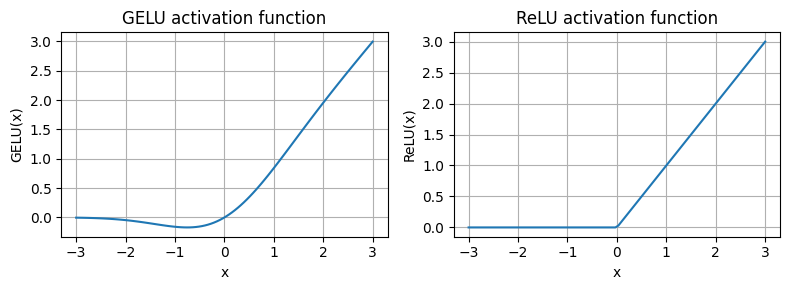

In [81]:
#4.3
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (
            1 + torch.tanh(
                torch.sqrt(torch.tensor(2.0 / torch.pi))
                * (x + 0.044715 * torch.pow(x, 3))
            )
        )

gelu = GELU()
relu = nn.ReLU()

x = torch.linspace(-3, 3, 100)

y_gelu = gelu(x)
y_relu = relu(x)

plt.figure(figsize=(8, 3))

for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [82]:
#4.4
import torch
import torch.nn as nn

class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()

        self.use_shortcut = use_shortcut

        self.layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(layer_sizes[0], layer_sizes[1]),
                GELU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[1], layer_sizes[2]),
                GELU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[2], layer_sizes[3]),
                GELU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[3], layer_sizes[4]),
                GELU()
            ),
            nn.Sequential(
                nn.Linear(layer_sizes[4], layer_sizes[5]),
                GELU()
            )
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)

            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output

        return x


layer_sizes = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)

model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes,
    use_shortcut=True
)

print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169792652130127
layers.1.0.weight has gradient mean of 0.20694108307361603
layers.2.0.weight has gradient mean of 0.3289699852466583
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


In [83]:
#4.5
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out must be divisible by num_heads"
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),diagonal=1)
    )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(
            b, num_tokens, self.num_heads, self.head_dim
        )
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)
        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)
        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)
        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out
        )
        context_vec = self.out_proj(context_vec)
        return context_vec
import torch
import torch.nn as nn
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )

        self.ff = FeedForward(cfg)

        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])

        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # First residual block (Attention)
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        # Second residual block (Feed Forward)
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x


torch.manual_seed(123)

x = torch.rand(2, 4, GPT_CONFIG_124M["emb_dim"])

block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 256])
Output shape: torch.Size([2, 4, 256])


In [84]:
#4.6
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()

        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])

        self.out_head = nn.Linear(
            cfg["emb_dim"],
            cfg["vocab_size"],
            bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape

        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)
        )

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)

        logits = self.out_head(x)

        return logits


torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)

out = model(batch)

print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

total_params_gpt2 = (
    total_params
    - sum(p.numel() for p in model.out_head.parameters())
)

print(
    f"Number of trainable parameters considering weight tying: "
    f"{total_params_gpt2:,}"
)

total_size_bytes = total_params * 4  # float32 = 4 bytes
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[-0.2046, -0.4997,  0.0155,  ...,  1.5172,  0.4412,  0.2224],
         [-1.0671,  1.0246, -0.4714,  ...,  0.0102,  0.0369, -0.9122],
         [-0.7380,  0.5224,  0.1489,  ...,  0.7364,  0.1893,  0.3514],
         [-0.0073,  0.1659, -0.4664,  ...,  0.1174,  0.3524,  0.6572]],

        [[-0.3268, -0.3022, -0.3400,  ...,  1.1306,  0.9008,  0.0589],
         [-0.6703,  0.9582, -0.7138,  ...,  0.3236, -0.1044, -1.8143],
         [-0.9269,  0.3472, -0.0063,  ...,  0.1226,  0.7168, -0.0308],
         [ 0.2969,  0.3415, -0.4662,  ..., -0.3656, -0.3483,  0.8095]]],
       grad_fn=<UnsafeViewBackward0>)
Total number of parameters: 28,953,600
Token embedding layer shape: torch.Size([50257, 256])
Output layer shape: torch.Size([50257, 256])
Number of trainable parameters considering weight tying: 16,087,808
Total size of the model: 110.45 MB


In [85]:
#4.7
def generate_text_simple(
    model,
    idx,
    max_new_tokens,
    context_size,
    temperature=1.0,
    top_k=None,
):

    for _ in range(max_new_tokens):

        # Keep only the last context_size tokens
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        # Take logits for the last generated token
        logits = logits[:, -1, :]

        # ---------- Top-k Sampling ----------
        if top_k is not None:
            top_logits, _ = torch.topk(logits, top_k)

            min_val = top_logits[:, -1]

            logits = torch.where(
                logits < min_val.unsqueeze(-1),
                torch.tensor(float("-inf"), device=logits.device),
                logits,
            )

        # ---------- Temperature Scaling ----------
        if temperature > 0:
            logits = logits / temperature

            probs = torch.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs,
                num_samples=1
            )

        else:
            # Greedy decoding (same behavior as before)
            idx_next = torch.argmax(
                logits,
                dim=-1,
                keepdim=True
            )

        # Append predicted token
        idx = torch.cat((idx, idx_next), dim=1)

    return idx


start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

model.eval()

out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"],
    temperature=0.8,
    top_k=40,
)

print("Output:", out)
print("Output length:", len(out[0]))

decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])
Output: tensor([[15496,    11,   314,   716, 11437, 48695, 40436, 31011, 31348, 45241]])
Output length: 10
Hello, I amenez vacationsHyd 299 sparedrums


In [86]:
#5.1
import torch
import tiktoken


GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 256,
    "n_heads": 4,
    "n_layers": 4,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)
model.eval()


def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(
        text, allowed_special={"<|endoftext|>"}
    )
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)
    return tokenizer.decode(flat.tolist())


start_context = "Every effort moves you"

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"],
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

text_data = tiny_stories_text

total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))

train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0,
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0,
)

print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

inputs, targets = next(iter(train_loader))

with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1)

seq_idx = torch.arange(targets.shape[1])

text_idx = 0
target_probas_1 = probas[text_idx, seq_idx, targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, seq_idx, targets[text_idx]]
print("Text 2:", target_probas_2)

target_probas = torch.cat((target_probas_1, target_probas_2))
log_probas = torch.log(target_probas)

avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

neg_avg_log_probas = -avg_log_probas
print(neg_avg_log_probas)

target_probas = torch.cat((target_probas_1, target_probas_2))
log_probas = torch.log(target_probas)

avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

neg_avg_log_probas = -avg_log_probas
print(neg_avg_log_probas)

print("Logits shape:", logits.shape)
print("Targets shape:", targets.shape)

logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

loss = torch.nn.functional.cross_entropy(
    logits_flat,
    targets_flat,
)

print(loss)


def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)

    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1),
        target_batch.flatten(),
    )

    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.0

    if len(data_loader) == 0:
        return float("nan")

    if num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i >= num_batches:
            break
        loss = calc_loss_batch(
            input_batch,
            target_batch,
            model,
            device,
        )
        total_loss += loss.item()
    return total_loss / num_batches

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Output text:
 Every effort moves you fetal timber grandmaMods sworn envoy Glad Hem lynoperator
Characters: 403432
Tokens: 98815
Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256

Ep 1 (Step 000000): Train loss 10.819, Val loss 10.808
Ep 1 (Step 000050): Train loss 6.026, Val loss 6.164
Ep 1 (Step 000100): Train loss 5.363, Val loss 5.647
Ep 1 (Step 000150): Train loss 5.109, Val loss 5.361
Once upon a time to the park in the sun smiled and the end. So you. He was so happy. He said, "Yes. I and he saw a big. They a time. She. But he was�€     One it
Ep 2 (Step 000200): Train loss 4.864, Val loss 5.208
Ep 2 (Step 000250): Train loss 4.754, Val loss 5.096
Ep 2 (Step 000300): Train loss 4.462, Val loss 4.984
Once upon a time there was so happy.  Tim€œI of the best and said "Don." You like the lady's old the other to the bird so and said, I. They were happy and her.    Once upon a
Ep 3 (Step 000350): Train loss 4.395, Val loss 4.920
Ep 3 (Step 000400): Train loss 4.174, Val loss 4.890
Ep 3 (Step 000450): Train loss 4.244, Val loss 4.816
Ep 3 (Step 000500): Train loss 4.093, Val loss 4.795
Once upon a time, a small girl.   L was very curious the water and said, "That

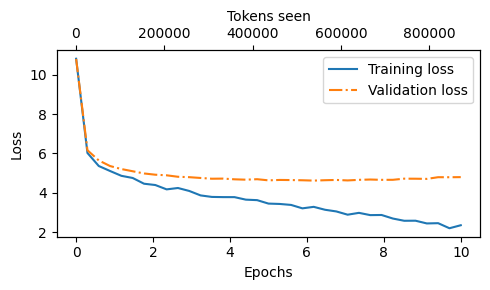

In [87]:
#5.2
def train_model_simple(
    model,
    train_loader,
    val_loader,
    optimizer,
    device,
    num_epochs,
    eval_freq,
    eval_iter,
    start_context,
    tokenizer,
):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()

            loss = calc_loss_batch(
                input_batch,
                target_batch,
                model,
                device,
            )

            loss.backward()
            optimizer.step()

            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model,
                    train_loader,
                    val_loader,
                    device,
                    eval_iter,
                )

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)

                print(
                    f"Ep {epoch+1} "
                    f"(Step {global_step:06d}): "
                    f"Train loss {train_loss:.3f}, "
                    f"Val loss {val_loss:.3f}"
                )

        generate_and_print_sample(
            model,
            tokenizer,
            device,
            start_context,
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(
    model,
    train_loader,
    val_loader,
    device,
    eval_iter,
):
    model.eval()

    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader,
            model,
            device,
            num_batches=eval_iter,
        )

        val_loss = calc_loss_loader(
            val_loader,
            model,
            device,
            num_batches=eval_iter,
        )

    model.train()

    return train_loss, val_loss


def generate_and_print_sample(
    model,
    tokenizer,
    device,
    start_context,
):
    model.eval()

    context_size = model.pos_emb.weight.shape[0]

    encoded = text_to_token_ids(
        start_context,
        tokenizer,
    ).to(device)

    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model,
    idx=encoded,
    max_new_tokens=50,
    context_size=context_size,
    temperature=0.8,
    top_k=40,
)

    decoded_text = token_ids_to_text(
        token_ids,
        tokenizer,
    )

    print(decoded_text.replace("\n", " "))

    model.train()


torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)
model.to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004,
    weight_decay=0.1,
)

num_epochs = 10

train_losses, val_losses, tokens_seen = train_model_simple(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=10,
    eval_freq=50,
    eval_iter=5,
    start_context="Once upon a time",
    tokenizer=tokenizer,
)

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(
    epochs_seen,
    tokens_seen,
    train_losses,
    val_losses,
):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(
        epochs_seen,
        train_losses,
        label="Training loss",
    )

    ax1.plot(
        epochs_seen,
        val_losses,
        linestyle="-.",
        label="Validation loss",
    )

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")

    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(
        MaxNLocator(integer=True)
    )

    ax2 = ax1.twiny()

    ax2.plot(
        tokens_seen,
        train_losses,
        alpha=0,
    )

    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()
    plt.show()


epochs_tensor = torch.linspace(
    0,
    num_epochs,
    len(train_losses),
)

plot_losses(
    epochs_tensor,
    tokens_seen,
    train_losses,
    val_losses,
)

In [89]:
torch.save(model.state_dict(), "StoryGPT.pth")

print("Model saved successfully!")

Model saved successfully!


In [90]:
# Final StoryGPT generation

model.eval()

prompt = "Once upon a time"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(prompt, tokenizer).to(device),
    max_new_tokens=150,
    context_size=GPT_CONFIG_124M["context_length"],
    temperature=0.8,
    top_k=40,
)

generated_text = token_ids_to_text(token_ids, tokenizer)

print("Prompt:", prompt)
print("\nGenerated story:")
print(generated_text)

Prompt: Once upon a time

Generated story:
Once upon a time, there was a girl named Tom. Her mom smiled and walked girl named Daisy. She loved to play. One day, she wanted the book. She saw that her eyes. One day, her friends. She was very sad because she saw something special. Emmy was very much better than to explore the door and dad for her. She held her mom told her and she was time, she was very curious, so she was so much better. She asked her lunch.


Mama and looked so she thought it was so clever and she would get out it was so happy with her bike. She hugged her mommy gave her own life to her favorite friend, she was a big ears and he could make her mom that she had
